# Pizza Review Sentiment with an RNN

Classifying short pizza reviews (English and Malay) as negative, neutral or positive: a SimpleRNN baseline trained on English reviews, then a bidirectional LSTM trained on English plus machine-translated Malay reviews, with text augmentation and Keras Tuner.

Both models use **one shared, stratified train/validation/test split** and are scored on the **same test reviews**, so the comparison is fair.

**Data:** `data/Pizza_reviews.csv`, 902 reviews with a 0–10 score and a language label. English translations of the Malay reviews are in `data/malay_translations.csv`.

## 1. Background Research

### 1.1 Recurrent Neural Networks (RNN)

**Recurrent Neural Networks** are designed for sequential data. Unlike feedforward networks, RNNs maintain a **hidden state** that carries information from previous time steps, making them well-suited for tasks where word order matters — such as sentiment analysis.

However, vanilla RNNs suffer from the **vanishing gradient problem**: gradients shrink exponentially during backpropagation through long sequences, causing the model to forget early context.

### 1.2 Long Short-Term Memory (LSTM)

**LSTM**, introduced by Hochreiter & Schmidhuber (1997), solves vanishing gradients via three gating mechanisms:

| Gate | Function |
|------|----------|
| **Input gate** | Controls how much new information enters the cell state |
| **Forget gate** | Controls how much old information to discard |
| **Output gate** | Controls what portion of the cell state becomes the hidden state |

This allows LSTMs to selectively retain long-range dependencies — critical for pizza reviews where sentiment cues may appear anywhere (e.g. *"...but the service ruined the experience"*).

### 1.3 Bidirectional LSTM (BiLSTM)

A **Bidirectional LSTM** runs two LSTMs simultaneously — one left-to-right, one right-to-left — and concatenates the outputs. This gives access to both past and future context at every token position, which is particularly valuable for sentiment classification involving negation (*"not bad at all"*).

### 1.4 Why Classification over Regression

The raw `Score` column contains extreme noise (values from –42 to 1010, non-numeric entries). Regression on such labels would produce unstable gradients. Instead we map scores to **3 ordinal sentiment classes**:

| Class | Label | Score Range |
|-------|-------|-------------|
| Negative | 0 | score ≤ 4 |
| Neutral | 1 | 4 < score ≤ 6 |
| Positive | 2 | score > 6 |

### 1.5 Language Decision

The dataset contains **English (~55%)**, **Malay (~45%)**, and minor Chinese/other content. We keep the Malay reviews and translate them to English (section 4.8). Discarding ~45% of a 902-row corpus would severely limit model generalisation, particularly for the smaller classes.


## 2. Imports & Configuration

All libraries are imported here and a global random seed of **42** is set across NumPy, Python's `random`, and TensorFlow to maximise reproducibility. TensorFlow version detected: **2.10.0**.

Key libraries used:
- `tensorflow` / `keras` — model building, training, tokenization, padding
- `sklearn` — train/test split, class weight computation, evaluation metrics
- `keras_tuner` — Hyperband hyperparameter search
- `nltk` — WordNetLemmatizer for text normalisation
- `pandas`, `numpy`, `matplotlib`, `seaborn` — data handling and visualisation


In [1]:
import os
import random
import time
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
import keras_tuner as kt
import matplotlib.pyplot as plt
import seaborn as sns

# Keras text utilities and layers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, SimpleRNN, Dense, Bidirectional, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

# Lemmatisation and WordNet synonyms (used by the improved model only)
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

# Set seeds for reproducibility
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
seed_everything(42)

# NLTK data for sentence splitting and WordNet
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("TensorFlow Version:", tf.__version__)
print("Environment successfully initialized with global seed 42.")

TensorFlow Version: 2.10.0
Environment successfully initialized with global seed 42.


## 3. Exploratory Data Analysis (EDA)

Before building any model, we examine the raw dataset to understand its structure and identify data quality issues. This section answers four questions:

1. How are sentiment classes distributed — is there class imbalance?
2. Are there invalid or extreme scores that need cleaning?
3. How long are the reviews — what `MAX_LEN` is appropriate?
4. What languages are present — how should non-English reviews be handled?


### 3.1 Sentiment Distribution

We apply the same sentiment mapping used in cleaning (score ≤ 4 → Negative, 4 < score ≤ 6 → Neutral, score > 6 → Positive) to the raw dataset for an early look at class balance before any rows are removed.


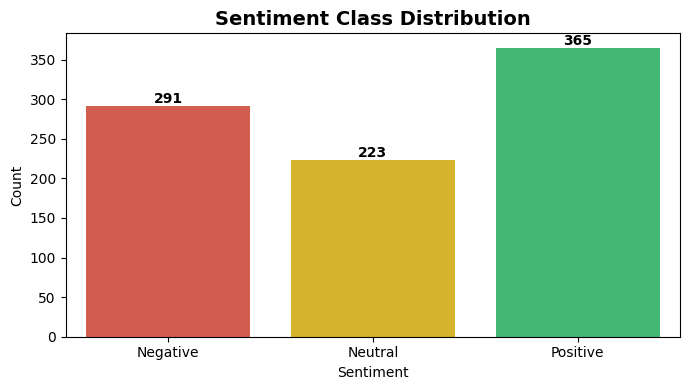

=== EXACT SENTIMENT PERCENTAGES ===
Sentiment
Positive    41.52 %
Negative    33.11 %
Neutral     25.37 %
Name: proportion, dtype: object


In [2]:
# Build a quick EDA dataframe with sentiment labels
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df_eda = pd.read_csv('data/Pizza_reviews.csv')
df_eda['Review'] = df_eda['Review'].astype(str).str.strip().str.lower()
df_eda['Score'] = pd.to_numeric(df_eda['Score'], errors='coerce')
df_eda = df_eda.dropna(subset=['Score'])
# Valid scores are 0–10; low values like 0.1 or 0.5 are real (very negative) ratings
df_eda = df_eda[(df_eda['Score'] >= 0) & (df_eda['Score'] <= 10)]

def map_sentiment(score):
    if score <= 4:   return 'Negative'
    elif score <= 6: return 'Neutral'
    else:            return 'Positive'

df_eda['Sentiment'] = df_eda['Score'].apply(map_sentiment)

# Plot sentiment distribution
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    x='Sentiment',
    data=df_eda,
    order=['Negative','Neutral','Positive'],
    hue='Sentiment',
    palette={'Negative': '#e74c3c', 'Neutral': '#f1c40f', 'Positive': '#2ecc71'},
    legend=False
)

plt.title('Sentiment Class Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Sentiment')
plt.ylabel('Count')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("=== EXACT SENTIMENT PERCENTAGES ===")
print(df_eda['Sentiment'].value_counts(normalize=True).mul(100).round(2).astype(str) + ' %')


**Observations — Sentiment Distribution**

| Sentiment | Share |
|-----------|-------|
| Positive  | 41.52% |
| Negative  | 33.11% |
| Neutral   | 25.37% |

The dataset is **moderately imbalanced** — Positive reviews are the majority class at 41.52%, while Neutral is the minority at 25.37%. The Positive-to-Neutral ratio is roughly 1.6:1. This imbalance is addressed downstream using **class weights** computed from the training split, which scale the loss function to penalise misclassification of minority classes more heavily. No oversampling or undersampling is applied, preserving all available training data.


### 3.2 Score Distribution & Outliers

The raw `Score` column is examined before cleaning to confirm the presence of invalid entries. The histogram shows the valid 0–10 range; the boxplot reveals the extent of extreme outliers.


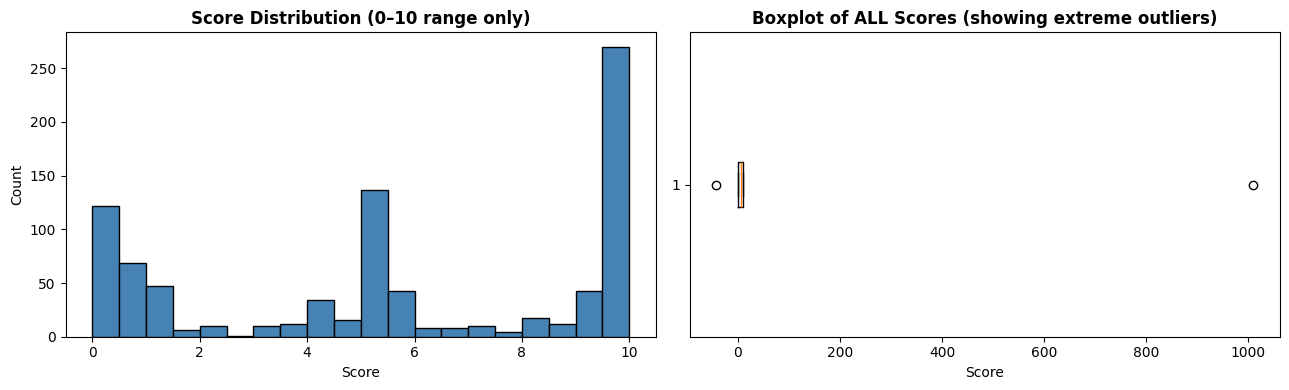

Min score (raw): -42.0
Max score (raw): 1010.0
Rows outside 0-10 range: 18
NaN scores (non-numeric): 5


In [3]:
# Reload the raw data to see the outliers before cleaning
df_raw = pd.read_csv('data/Pizza_reviews.csv')
df_raw['Score'] = pd.to_numeric(df_raw['Score'], errors='coerce')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

# Histogram (valid 0–10 range only for visibility)
clean_scores = df_raw['Score'].dropna()
ax1.hist(clean_scores[(clean_scores >= 0) & (clean_scores <= 10)], bins=20,
         color='steelblue', edgecolor='black')
ax1.set_title('Score Distribution (0–10 range only)', fontweight='bold')
ax1.set_xlabel('Score'); ax1.set_ylabel('Count')

# Boxplot showing outliers
ax2.boxplot(clean_scores.dropna(), vert=False)
ax2.set_title('Boxplot of ALL Scores (showing extreme outliers)', fontweight='bold')
ax2.set_xlabel('Score')

plt.tight_layout()
plt.show()

print(f"Min score (raw): {clean_scores.min()}")
print(f"Max score (raw): {clean_scores.max()}")
print(f"Rows outside 0-10 range: {((clean_scores < 0) | (clean_scores > 10)).sum()}")
print(f"NaN scores (non-numeric): {df_raw['Score'].isna().sum()}")


**Observations — Score Distribution & Outliers**

| Metric | Value |
|--------|-------|
| Raw score minimum | –42.0 |
| Raw score maximum | 1010.0 |
| Rows outside valid 0–10 range | 18 |
| Non-numeric scores (NaN after coercion) | 5 |

Two categories of invalid scores are present:
- **5 non-numeric entries** — text values such as `"good"` coerced to `NaN` by `pd.to_numeric(errors='coerce')` and dropped
- **18 out-of-range entries** — extreme values (–42, 1010) that are clearly data-entry errors, removed by filtering `Score >= 0` and `Score <= 10`

The valid range starts at **0**, not 1. Scores of 0, 0.1, and 0.5 are legitimate very-low ratings and are retained as Negative sentiment.


### 3.3 Review Length Analysis

Review length directly determines `MAX_LEN` — the sequence length all reviews are padded or truncated to before being fed into the RNN. Setting `MAX_LEN` too short silently truncates longer reviews; setting it to the maximum ensures no review loses any tokens.


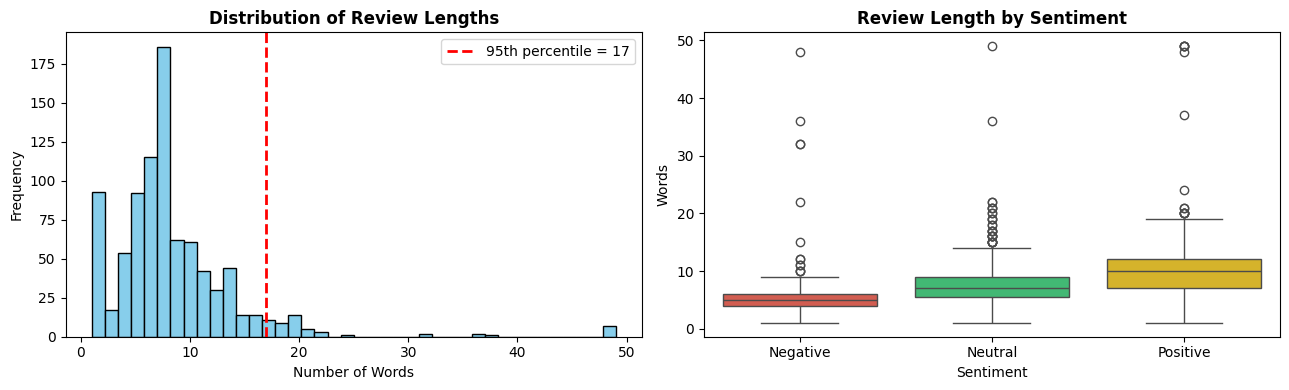

count    879.00
mean       8.29
std        5.93
min        1.00
25%        5.00
50%        7.00
75%       10.00
max       49.00
Name: Review_Length, dtype: float64


In [4]:
df_eda['Review_Length'] = df_eda['Review'].apply(lambda x: len(str(x).split()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.hist(df_eda['Review_Length'], bins=40, color='skyblue', edgecolor='black')
p95 = int(np.percentile(df_eda['Review_Length'], 95))
ax1.axvline(p95, color='red', linestyle='--', linewidth=2, label=f'95th percentile = {p95}')
ax1.set_title('Distribution of Review Lengths', fontweight='bold')
ax1.set_xlabel('Number of Words'); ax1.set_ylabel('Frequency')
ax1.legend()

sns.boxplot(x='Sentiment', y='Review_Length', data=df_eda,
            hue='Sentiment',
            order=['Negative','Neutral','Positive'],
            palette=['#e74c3c','#f1c40f','#2ecc71'], 
            legend=False,
            ax=ax2)
ax2.set_title('Review Length by Sentiment', fontweight='bold')
ax2.set_xlabel('Sentiment'); ax2.set_ylabel('Words')

plt.tight_layout()
plt.show()

print(df_eda['Review_Length'].describe().round(2))


**Observations — Review Length**

| Statistic | Value |
|-----------|-------|
| Count (valid reviews) | 879 |
| Mean word count | 8.29 words |
| Median word count | 7.00 words |
| 75th percentile | 10.00 words |
| Maximum | 49 words |

Pizza reviews are predominantly **short, informal comments** — the median is only 7 words. Two decisions follow from this:

1. **`MAX_LEN`** is later set to the longest *training* review (section 4.11) rather than the 95th percentile (17 words), because the longest reviews tend to hold the most nuanced, multi-clause opinions. No training review is cut off; a test review longer than that would be truncated.

2. The **high proportion of zero-padding** (most sequences are ≤10 tokens out of 48) makes `mask_zero=True` in the Embedding layer critical — without it, the RNN would process padding zeros as real tokens, adding noise to the hidden state.


### 3.4 Language Distribution

The dataset is multilingual. Understanding the language split determines whether non-English reviews should be discarded or translated, and directly motivates the two-track (Baseline vs Improved) approach.


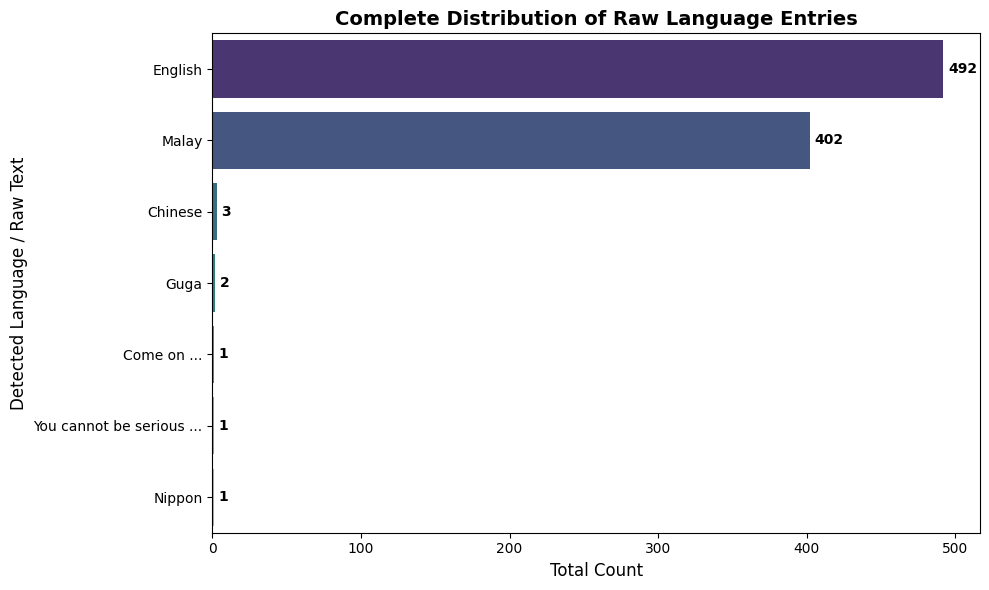

=== EXACT RAW BREAKDOWN ===
Language
English                      54.55 %
Malay                        44.57 %
Chinese                       0.33 %
Guga                          0.22 %
Come on ...                   0.11 %
You cannot be serious ...     0.11 %
Nippon                        0.11 %
Name: proportion, dtype: object


In [5]:
# Raw language labels, before any cleaning
language_counts = df_raw['Language'].value_counts()

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    y=language_counts.index,
    x=language_counts.values,
    hue=language_counts.index,
    palette='viridis',
    legend=False
)

plt.title('Complete Distribution of Raw Language Entries', fontsize=14, fontweight='bold')
plt.xlabel('Total Count', fontsize=12)
plt.ylabel('Detected Language / Raw Text', fontsize=12)

# Label each bar with its count
for p in ax.patches:
    ax.annotate(f'{int(p.get_width())}',
                (p.get_width() + 3, p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("=== EXACT RAW BREAKDOWN ===")
print(df_raw['Language'].value_counts(normalize=True).mul(100).round(2).astype(str) + ' %')

**Observations — Language Distribution**

| Language | Share |
|----------|-------|
| English | 54.55% |
| Malay | 44.57% |
| Chinese | 0.33% |
| Invalid labels (Guga, Come on..., Nippon, etc.) | 0.55% |

The dataset is close to a 55/45 English–Malay split. That drives the main design decision: instead of discarding almost half the data, the improved model also learns from the Malay reviews, translated to English (section 4.8). The few Chinese rows and invalid language labels are dropped in section 4.7.

This gives two models to compare:
- **Baseline:** trained on English reviews only
- **Improved:** trained on English plus translated Malay reviews

## 4. Data Cleaning & Pre-processing

The raw dataset requires several cleaning steps before tokenization. Each step is applied in a specific order — in particular, conflicting label removal happens **after** sentiment labels are created, so conflicts are detected at the class level rather than the raw numeric score level.


### 4.1 Pre-processing pipeline

| Step | Action | Rows after |
|------|--------|:----------:|
| Load | Read CSV, strip and lowercase the review text | 902 |
| Drop column | Remove the near-empty 4th column | 902 |
| Score cleaning | Drop non-numeric and out-of-range scores | 879 |
| Empty reviews | Drop blank reviews | 879 |
| Exact duplicates | Drop identical (review, label) pairs | 800 |
| Conflicting labels | Drop reviews that appear with more than one sentiment | 768 |
| Language filter | Keep English and Malay only | see 4.7 |
| Translation | Malay → English from `data/malay_translations.csv` | — |
| Lemmatisation | Verb- and noun-aware WordNet lemmatisation (improved model only) | — |
| Split | One split, stratified by sentiment and language: 15% test, then 15% of the rest for validation | — |
| Tokenization | Fitted on each model's **training** text only | — |

In [6]:
# Load the raw data
df = pd.read_csv('data/Pizza_reviews.csv')

# Strip whitespace and lowercase the review text
df['Review'] = df['Review'].astype(str).str.strip().str.lower()

print(f"Total raw dataset records loaded: {len(df)}")
print(f"Columns: {list(df.columns)}")


Total raw dataset records loaded: 902
Columns: ['Review', 'Score', 'Are there ways for you to generate more data? Spliting up sentences, would that help?', 'Language']


### 4.2 Drop Irrelevant Column

The raw CSV contains a 4th column with the text `"Are there ways for you to generate more data? Spliting up sentences, would that help?"`. This column has fewer than 3 non-null values across 902 rows and carries no useful modelling signal. It is dropped immediately after loading.


In [7]:
# Drop the near-empty 4th column (it only holds a stray question)

JUNK_COL = "Are there ways for you to generate more data? Spliting up sentences, would that help?"

if JUNK_COL in df.columns:
    df = df.drop(columns=[JUNK_COL])
    print(f"Dropped irrelevant column. Remaining columns: {list(df.columns)}")
else:
    print(f"Column not found (already absent). Columns: {list(df.columns)}")


Dropped irrelevant column. Remaining columns: ['Review', 'Score', 'Language']


**Result:** Irrelevant column successfully dropped. Remaining columns: `Review`, `Score`, `Language`.


### 4.3 Score Cleaning & Outlier Removal

The `Score` column is coerced to numeric (non-parseable entries become `NaN`), then filtered to the valid range 0–10. Scores are then mapped to 3 ordinal sentiment classes.

**Why 3 classes instead of regression?**  
Predicting an exact numeric score from short informal text is unreliable — the same review could plausibly score 7.5 or 8.2 depending on the reviewer's personal scale. Mapping to 3 classes (Negative / Neutral / Positive) produces a more stable and practically useful output.

**Sentiment mapping:**
- Score ≤ 4 → **Negative** (0)
- 4 < score ≤ 6 → **Neutral** (1)
- Score > 6 → **Positive** (2)


In [8]:
# ─────────────────────────────────────────────────────────
# STEP 1–3: Score cleaning, outlier removal & sentiment mapping
# ─────────────────────────────────────────────────────────

# Coerce Score to numeric — non-numeric entries (e.g. "good") become NaN
df['Score'] = pd.to_numeric(df['Score'], errors='coerce')

# Drop rows where Score is NaN (non-parseable entries)
before_drop = len(df)
df = df.dropna(subset=['Score'])
print(f"Dropped {before_drop - len(df)} rows with non-numeric scores.")

# Scores like 0, 0.1, 0.5 are legitimate very-low (Negative) ratings
before_outlier = len(df)
df = df[(df['Score'] >= 0) & (df['Score'] <= 10)]
print(f"Dropped {before_outlier - len(df)} rows with out-of-range scores (valid range: 0–10).")
print(f"Remaining rows after score cleaning: {len(df)}")

# Map numeric scores to 3 ordinal sentiment classes
def map_sentiment(score):
    if score <= 4:   return 0   # Negative
    elif score <= 6: return 1   # Neutral
    else:            return 2   # Positive

df['Label'] = df['Score'].apply(map_sentiment)

label_names = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
print("\nSentiment class distribution after score cleaning:")
print(df['Label'].map(label_names).value_counts())


Dropped 5 rows with non-numeric scores.
Dropped 18 rows with out-of-range scores (valid range: 0–10).
Remaining rows after score cleaning: 879

Sentiment class distribution after score cleaning:
Label
Positive    365
Negative    291
Neutral     223
Name: count, dtype: int64


**Cleaning Results — Score:**

| Step | Rows removed | Rows remaining |
|------|:---:|:---:|
| Start | — | 902 |
| Non-numeric scores dropped | 5 | 897 |
| Out-of-range scores (< 0 or > 10) dropped | 18 | 879 |

**Sentiment distribution after cleaning:**

| Sentiment | Count |
|-----------|-------|
| Positive | 365 |
| Negative | 291 |
| Neutral | 223 |


### 4.4 Remove Empty / Missing Reviews

Reviews that are empty strings or contain only whitespace cannot be tokenized and provide no training signal.


In [9]:
# ─────────────────────────────────────────────────────────
# STEP 4: Remove empty or missing reviews
# ─────────────────────────────────────────────────────────

before = len(df)
df = df[df['Review'].str.strip().str.len() > 0]
print(f"Dropped {before - len(df)} empty/whitespace reviews.")
print(f"Remaining rows: {len(df)}")


Dropped 0 empty/whitespace reviews.
Remaining rows: 879


**Result:** 0 empty or whitespace-only reviews found. All 879 remaining rows contain meaningful review text. The earlier `.str.strip().str.lower()` standardisation step successfully handled any leading/trailing whitespace.


### 4.5 Remove Exact Duplicate Rows

Rows where both the `Review` text and `Label` are identical are removed. Retaining exact duplicates would cause the model to see the same example multiple times per epoch, effectively over-weighting those specific phrases in the loss function.

Note: duplicates are checked at the `(Review, Label)` level — not just `Review`. The same review text with *different* labels represents a conflict, handled separately in the next step.


In [10]:
# ─────────────────────────────────────────────────────────
# STEP 5a: Remove exact duplicate rows (same Review + same Label)
# ─────────────────────────────────────────────────────────

before = len(df)
df = df.drop_duplicates(subset=['Review', 'Label'])
print(f"Dropped {before - len(df)} exact duplicate (Review, Label) pairs.")
print(f"Remaining rows: {len(df)}")


Dropped 79 exact duplicate (Review, Label) pairs.
Remaining rows: 800


**Result:** 79 exact `(Review, Label)` duplicate pairs removed, leaving **800 rows**.


### 4.6 Remove Conflicting Sentiment Labels

Reviews that appear with more than one sentiment class across different rows are removed entirely. For example, a review scored as both 3 (Negative) and 8 (Positive) by different entries creates a direct contradiction — the model receives identical input tokens but is trained toward opposing targets, introducing gradient conflict.

**Why check at label level, not raw score level?**  
Two scores of 0.1 and 0.8 are numerically different but both map to Negative — no real conflict at the class level. Removing based on raw score differences would incorrectly discard these consistent rows. Checking after label creation removes only genuine class-level contradictions.


In [11]:
# ─────────────────────────────────────────────────────────
# STEP 5b: Remove reviews with conflicting SENTIMENT LABELS
# (checked at label level, not raw score level)
# ─────────────────────────────────────────────────────────

before = len(df)

# Find reviews whose text maps to more than one sentiment class
conflict_check = df.groupby('Review')['Label'].nunique()
conflicting_texts = conflict_check[conflict_check > 1].index

df = df[~df['Review'].isin(conflicting_texts)].copy()

print(f"Found {len(conflicting_texts)} review texts with conflicting sentiment labels.")
print(f"Dropped {before - len(df)} rows from those conflicting groups.")
print(f"Remaining rows after conflict removal: {len(df)}")
print("\nFinal sentiment distribution:")
print(df['Label'].map(label_names).value_counts())


Found 15 review texts with conflicting sentiment labels.
Dropped 32 rows from those conflicting groups.
Remaining rows after conflict removal: 768

Final sentiment distribution:
Label
Positive    343
Negative    221
Neutral     204
Name: count, dtype: int64


### 4.7 Language filter

Only English and Malay reviews are kept. The few Chinese reviews and rows with invalid language labels are too rare to model.

In [12]:
# Keep English and Malay reviews; drop the few Chinese rows and invalid language labels
df['Language'] = df['Language'].astype(str).str.strip().str.lower()
print("Language labels after cleaning:")
print(df['Language'].value_counts())

df = df[df['Language'].isin(['english', 'malay'])].reset_index(drop=True)
print(f"\nRows kept (English + Malay): {len(df)}")

Language labels after cleaning:
Language
english    420
malay      346
chinese      1
nippon       1
Name: count, dtype: int64

Rows kept (English + Malay): 766


**Result:** 766 reviews remain: 420 English and 346 Malay. The cleaning steps above had already removed most of the other labels, leaving one Chinese row and one "nippon" row to drop here.

### 4.8 Translating the Malay reviews

Rather than dropping almost half the data, the Malay reviews are translated to English. The translations were made with an AI model (Claude) and saved in `data/malay_translations.csv`, one row per unique Malay review. That makes reruns identical and removes any dependence on a live translation service.

Translation happens before the split. That's safe: it's a fixed text-to-text mapping that doesn't learn anything from the data.

In [13]:
# Malay reviews are translated from a saved file, so the notebook needs no translation service
translations = pd.read_csv('data/malay_translations.csv')
translation_map = dict(zip(translations['malay'], translations['english']))

malay_mask = df['Language'] == 'malay'
print(f"Malay reviews: {malay_mask.sum()}  (unique: {df.loc[malay_mask, 'Review'].nunique()})")

# Review_en: English text for every row (original English, or the Malay translation)
df['Review_en'] = df['Review']
df.loc[malay_mask, 'Review_en'] = df.loc[malay_mask, 'Review'].map(translation_map)
assert df['Review_en'].notna().all(), "Some Malay reviews have no translation"

print("\nExample translations:")
print(df.loc[malay_mask, ['Review', 'Review_en']].head(5).to_string(index=False))

Malay reviews: 346  (unique: 346)

Example translations:
                                                               Review                                                                       Review_en
pizza ini sangat sedap, sambalnya memberi rasa yang unik dan menarik. this pizza is very delicious, the sambal gives a unique and interesting flavor.
               rasa satay dan mayo tidak seimbang, agak mengecewakan.               the satay and mayo flavors are not balanced, quite disappointing.
   crustnya lembut tapi topping sambal agak terlalu pedas untuk saya.             the crust is soft but the sambal topping is a bit too spicy for me.
                         saya suka campuran rasa ini, unik dan lazat!                               i like this mix of flavors, unique and delicious!
                 pizza ni biasa-biasa saja, tak ada apa yang menarik.                       this pizza is just average, nothing interesting about it.


**Result:** all 346 Malay reviews (every one unique) have an English translation. The translations use American spelling (*"flavor"*), matching the English reviews, so the same word gets the same token in both languages.

### 4.9 Lemmatisation (improved model only)

WordNet's lemmatiser treats every word as a noun by default, which turns *"was"* into *"wa"* and *"has"* into *"ha"*. Lemmatising each word as a verb first and then as a noun avoids that.

In [14]:
lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    """Lemmatise each word as a verb, then as a noun ('was' -> 'be', 'pizzas' -> 'pizza')."""
    return ' '.join(lemmatizer.lemmatize(lemmatizer.lemmatize(w, 'v'), 'n') for w in str(text).split())

df['Review_lemma'] = df['Review_en'].apply(lemmatize_text)

for before in ['the crust was soggy and the sauces were bland.', 'loved the pizzas, would order again']:
    print(f"{before!r:50} -> {lemmatize_text(before)!r}")

'the crust was soggy and the sauces were bland.'   -> 'the crust be soggy and the sauce be bland.'
'loved the pizzas, would order again'              -> 'love the pizzas, would order again'


### 4.10 One shared train / validation / test split

The data is split **once**, before any model-specific step, and the split is **stratified by sentiment and language together**, so every subset has the same mix of classes and languages.

- **Test (15%):** held out until the final evaluation, and shared by both models
- **Validation (15% of the rest):** used for early stopping and the hyperparameter search
- **Train:** everything else

The baseline uses only the English reviews from each split. The improved model uses all of them.

In [15]:
# One split for both models, stratified by sentiment and language together
strata = df['Label'].astype(str) + '_' + df['Language']

train_df, test_df = train_test_split(df, test_size=0.15, random_state=42, stratify=strata)
train_df, val_df  = train_test_split(train_df, test_size=0.15, random_state=42, stratify=strata.loc[train_df.index])

for name, part in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    dist = part['Label'].map(label_names).value_counts(normalize=True).mul(100).round(1)
    print(f"{name:10} {len(part):4} rows | English {int((part['Language'] == 'english').sum()):3} | "
          f"Malay {int((part['Language'] == 'malay').sum()):3} | "
          f"Neg {dist.get('Negative', 0):4}%  Neu {dist.get('Neutral', 0):4}%  Pos {dist.get('Positive', 0):4}%")

# The baseline only sees English reviews from each split
train_en = train_df[train_df['Language'] == 'english']
val_en   = val_df[val_df['Language'] == 'english']
test_en  = test_df[test_df['Language'] == 'english']
print(f"\nBaseline (English only): train {len(train_en)}, validation {len(val_en)}, test {len(test_en)}")

Train       553 rows | English 304 | Malay 249 | Neg 28.6%  Neu 26.8%  Pos 44.7%
Validation   98 rows | English  53 | Malay  45 | Neg 28.6%  Neu 26.5%  Pos 44.9%
Test        115 rows | English  63 | Malay  52 | Neg 28.7%  Neu 26.1%  Pos 45.2%

Baseline (English only): train 304, validation 53, test 63


**Result**

| Split | Reviews | English | Malay | Negative / Neutral / Positive |
|---|:-:|:-:|:-:|:-:|
| Train | 553 | 304 | 249 | 28.6% / 26.8% / 44.7% |
| Validation | 98 | 53 | 45 | 28.6% / 26.5% / 44.9% |
| Test | 115 | 63 | 52 | 28.7% / 26.1% / 45.2% |

Stratifying keeps the class and language mix almost identical across the three splits. The baseline trains on the 304 English training reviews and is tuned on the 53 English validation reviews.

### 4.11 Baseline tokenization (training text only)

The tokenizer and the two size settings are computed from the **training reviews only**, so no test vocabulary leaks into the model:

- `MAX_WORDS`: words that appear more than twice in the training text; rarer words become `<OOV>`
- `MAX_LEN`: the longest training review; all sequences are padded to this length

In [16]:
def vocab_and_length(texts):
    """MAX_WORDS = words seen more than twice; MAX_LEN = longest review (training texts only)."""
    counter = Tokenizer()
    counter.fit_on_texts(texts)
    max_words = sum(1 for c in counter.word_counts.values() if c > 2)
    max_len = int(texts.apply(lambda t: len(str(t).split())).max())
    return max_words, max_len, len(counter.word_index)

MAX_WORDS, MAX_LEN, total_words = vocab_and_length(train_en['Review_en'])
print(f"Baseline: {total_words} unique training words, {MAX_WORDS} seen more than twice -> MAX_WORDS = {MAX_WORDS}")
print(f"Baseline: longest training review = {MAX_LEN} words -> MAX_LEN = {MAX_LEN}")

# Fit on the English training reviews only
base_tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
base_tokenizer.fit_on_texts(train_en['Review_en'])

def encode_base(texts):
    return pad_sequences(base_tokenizer.texts_to_sequences(texts), maxlen=MAX_LEN, padding='post')

X_train_base, y_train_base = encode_base(train_en['Review_en']), train_en['Label'].values
X_val_base,   y_val_base   = encode_base(val_en['Review_en']),   val_en['Label'].values

weights_b = compute_class_weight(class_weight='balanced', classes=np.unique(y_train_base), y=y_train_base)
class_weights_base = dict(zip(np.unique(y_train_base), weights_b))
print(f"\nTrain {X_train_base.shape}, validation {X_val_base.shape}")
print("Class weights:", {label_names[k]: round(v, 3) for k, v in class_weights_base.items()})

Baseline: 525 unique training words, 199 seen more than twice -> MAX_WORDS = 199
Baseline: longest training review = 48 words -> MAX_LEN = 48

Train (304, 48), validation (53, 48)
Class weights: {'Negative': 1.126, 'Neutral': 1.078, 'Positive': 0.844}


### Baseline model: SimpleRNN

`Embedding(MAX_WORDS, 16, mask_zero=True) → SimpleRNN(32) → Dense(3, softmax)`, trained on the English training reviews with class weights and early stopping (patience 3, up to 15 epochs).

SimpleRNN is the simplest recurrent layer: one hidden state, read left to right. It's prone to vanishing gradients, but most reviews are short, so it makes a reasonable floor.

In [17]:
start = time.time()

base_model = Sequential([
    # mask_zero=True makes the RNN skip the padding zeros
    Embedding(input_dim=MAX_WORDS, output_dim=16, input_length=MAX_LEN, mask_zero=True),
    SimpleRNN(32),
    Dense(3, activation='softmax')
])
base_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

base_history = base_model.fit(
    X_train_base, y_train_base,
    validation_data=(X_val_base, y_val_base),
    epochs=15,
    batch_size=32,
    class_weight=class_weights_base,
    callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
    verbose=2
)
print(f"\nEpochs run: {len(base_history.history['loss'])}, training time: {(time.time() - start) / 60:.2f} min")

Epoch 1/15


10/10 - 1s - loss: 1.0622 - accuracy: 0.4671 - val_loss: 1.0054 - val_accuracy: 0.4340 - 1s/epoch - 103ms/step


Epoch 2/15


10/10 - 0s - loss: 0.9561 - accuracy: 0.4934 - val_loss: 0.9546 - val_accuracy: 0.4717 - 76ms/epoch - 8ms/step


Epoch 3/15


...

Epoch 8/15


10/10 - 0s - loss: 0.4442 - accuracy: 0.8684 - val_loss: 0.7491 - val_accuracy: 0.7547 - 74ms/epoch - 7ms/step


Epoch 9/15


10/10 - 0s - loss: 0.4098 - accuracy: 0.8882 - val_loss: 0.7488 - val_accuracy: 0.7736 - 81ms/epoch - 8ms/step



Epochs run: 9, training time: 0.06 min


**Result:** early stopping ended training after 9 epochs and restored the weights with the lowest validation loss (epoch 6). The model has 4,851 parameters and trains in seconds.

---
## 5. Improved model

| Baseline limitation | Improvement |
|---|---|
| English reviews only | Malay reviews translated and added |
| No data augmentation | EDA augmentation on the training set (synonym replacement, random insertion) |
| SimpleRNN, left to right only | Bidirectional LSTM |
| No regularisation | Dropout 0.5 (×2), L2 on the LSTM, recurrent dropout 0.2, gradient clipping |
| Fixed hyperparameters | Keras Tuner Hyperband search |

### 5.1 Data augmentation (EDA, Wei & Zou 2019)

Applied to the **training set only**. Positive and negative reviews are split into sentences, which keep the review's label; neutral reviews stay whole, because their individual sentences are often positive or negative. Each sentence gets, with 60% probability, one augmented copy made with one of these, chosen at random:

| Method | What it does |
|---|---|
| Synonym replacement | Swaps up to 2 words for WordNet synonyms |
| Random insertion | Inserts synonyms of 2 random words at random positions |

Random deletion and random swap are left out, because they can flip the meaning of a 7-word review. The result is capped at 2× the original training size.

In [18]:
# Text augmentation (EDA): synonym replacement and random insertion.
# Synonyms are sorted so the augmentation is reproducible (set order changes between Python runs).
def get_synonyms(word):
    synonyms = set()
    for syn in wordnet.synsets(word):
        for lemma in syn.lemmas():
            syn_word = lemma.name().replace('_', ' ').lower()
            if syn_word != word.lower() and syn_word.isalpha():
                synonyms.add(syn_word)
    return sorted(synonyms)

def synonym_replacement(text, n=2):
    words = text.split()
    new_words = words.copy()
    candidates = sorted(set(w for w in words if get_synonyms(w)))
    random.shuffle(candidates)
    for word in candidates[:n]:
        synonym = random.choice(get_synonyms(word))
        new_words = [synonym if w == word else w for w in new_words]
    return ' '.join(new_words)

def random_insertion(text, n=2):
    words = text.split()
    new_words = words.copy()
    for _ in range(n):
        synonyms = get_synonyms(random.choice(words))
        if synonyms:
            new_words.insert(random.randint(0, len(new_words)), random.choice(synonyms))
    return ' '.join(new_words)

def augment_review(text, label):
    """Return the original sentence(s) plus, with 60% probability, one augmented version of each."""
    # Split positive and negative reviews into sentences; each sentence keeps the review's label.
    # Neutral reviews stay whole, because their individual sentences are often positive or negative.
    if label == 1:
        sentences = [text]
    else:
        sentences = [s.strip() for s in nltk.sent_tokenize(text) if len(s.strip()) > 8] or [text]

    rows = []
    for sent in sentences:
        rows.append({'Review': sent, 'Label': label})
        if random.random() > 0.4:
            # Random deletion and random swap are left out: in very short reviews they can change the meaning
            aug = synonym_replacement(sent) if random.random() < 0.5 else random_insertion(sent)
            if len(aug.strip()) > 5 and aug != sent:
                rows.append({'Review': aug, 'Label': label})
    return rows

seed_everything(42)
augmented = [r for text, label in zip(train_df['Review_lemma'], train_df['Label']) for r in augment_review(text, label)]

# Cap at 2x the original training size: too many near-duplicates make the model memorise variants
train_aug = pd.DataFrame(augmented).sample(frac=1, random_state=42).reset_index(drop=True).head(len(train_df) * 2)
print(f"Original training reviews : {len(train_df)}")
print(f"Augmented training rows   : {len(train_aug)}")
print("Label share (%):", train_aug['Label'].map(label_names).value_counts(normalize=True).mul(100).round(1).to_dict())

Original training reviews : 553
Augmented training rows   : 981
Label share (%): {'Positive': 49.9, 'Negative': 26.8, 'Neutral': 23.2}


**Result:** the training set grows from 553 reviews to 981 rows. Positive rows rise to about 50% of the augmented set, because positive and negative reviews are split into sentences while neutral reviews stay whole. The class weights in the next cell offset this (Positive 0.667, Neutral 1.434, Negative 1.243).

### 5.2 Improved tokenization (training text only)

The improved tokenizer is fitted on the augmented **training** text only. `IMP_MAX_LEN` is the longest original training review, so test reviews of normal length aren't cut off.

In [19]:
# Tokenizer fitted on the augmented TRAINING set only
IMP_MAX_WORDS, _, imp_total_words = vocab_and_length(train_aug['Review'])
IMP_MAX_LEN = int(train_df['Review_lemma'].apply(lambda t: len(t.split())).max())  # longest original training review
print(f"Improved: {imp_total_words} unique training words, {IMP_MAX_WORDS} seen more than twice -> IMP_MAX_WORDS = {IMP_MAX_WORDS}")
print(f"Improved: longest training review = {IMP_MAX_LEN} words -> IMP_MAX_LEN = {IMP_MAX_LEN}")

imp_tokenizer = Tokenizer(num_words=IMP_MAX_WORDS, oov_token="<OOV>")
imp_tokenizer.fit_on_texts(train_aug['Review'])

def encode_imp(texts):
    return pad_sequences(imp_tokenizer.texts_to_sequences(texts), maxlen=IMP_MAX_LEN, padding='post')

X_train_imp, y_train_imp = encode_imp(train_aug['Review']), train_aug['Label'].values
X_val_imp,   y_val_imp   = encode_imp(val_df['Review_lemma']), val_df['Label'].values

weights_i = compute_class_weight(class_weight='balanced', classes=np.unique(y_train_imp), y=y_train_imp)
class_weights_imp = dict(zip(np.unique(y_train_imp), weights_i))
print(f"\nTrain {X_train_imp.shape}, validation {X_val_imp.shape}")
print("Class weights:", {label_names[k]: round(v, 3) for k, v in class_weights_imp.items()})

Improved: 843 unique training words, 367 seen more than twice -> IMP_MAX_WORDS = 367
Improved: longest training review = 48 words -> IMP_MAX_LEN = 48

Train (981, 48), validation (98, 48)
Class weights: {'Negative': 1.243, 'Neutral': 1.434, 'Positive': 0.667}


### 5.3 Tunable bidirectional LSTM and Hyperband search

`Embedding → Dropout(0.5) → Bidirectional(LSTM) → Dropout(0.5) → Dense(3, softmax)`

A bidirectional LSTM reads each review in both directions, which helps with phrases like *"not bad at all"*. Hyperband searches 8 combinations (embedding size 32/64, LSTM units 16/32, learning rate 1e-3/1e-4) on the validation set. The final model is then retrained with the best settings, class weights and early stopping (patience 4, up to 20 epochs).

In [20]:
def build_tunable_model(hp):
    model = Sequential()
    model.add(Embedding(input_dim=IMP_MAX_WORDS,
                        output_dim=hp.Choice('embed_dim', values=[32, 64]),
                        input_length=IMP_MAX_LEN,
                        mask_zero=True))
    model.add(Dropout(0.5))  # fixed at 0.5 to keep the search small
    model.add(Bidirectional(LSTM(units=hp.Choice('lstm_units', values=[16, 32]),
                                 kernel_regularizer=l2(0.01),
                                 recurrent_dropout=0.2)))
    model.add(Dropout(0.5))
    model.add(Dense(3, activation='softmax'))

    lr = hp.Choice('learning_rate', values=[1e-3, 1e-4])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Search space: 2 x 2 x 2 = 8 combinations

In [21]:
start = time.time()
seed_everything(42)

tuner = kt.Hyperband(
    build_tunable_model,
    objective='val_accuracy',
    max_epochs=5,        # Hyperband drops weak trials early
    factor=3,
    directory='pizza_tuning',
    project_name='bilstm_search',
    overwrite=True,
    seed=42
)
tuner.search(X_train_imp, y_train_imp,
             epochs=8,
             validation_data=(X_val_imp, y_val_imp),
             callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
             verbose=0)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best hyperparameters:", {k: best_hps.get(k) for k in ['embed_dim', 'lstm_units', 'learning_rate']})
print(f"Best validation accuracy during the search: {tuner.oracle.get_best_trials(1)[0].score:.4f}")

# Train the final model with the best hyperparameters and normal patience
seed_everything(42)
imp_model = tuner.hypermodel.build(best_hps)
imp_history = imp_model.fit(
    X_train_imp, y_train_imp,
    validation_data=(X_val_imp, y_val_imp),
    epochs=20,
    batch_size=32,
    class_weight=class_weights_imp,
    callbacks=[EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)],
    verbose=2
)
print(f"\nEpochs run: {len(imp_history.history['loss'])}, total tuning + training time: {(time.time() - start) / 60:.2f} min")

Best hyperparameters: {'embed_dim': 64, 'lstm_units': 32, 'learning_rate': 0.001}
Best validation accuracy during the search: 0.7959


Epoch 1/20


31/31 - 7s - loss: 2.4238 - accuracy: 0.4322 - val_loss: 2.0537 - val_accuracy: 0.6224 - 7s/epoch - 227ms/step


Epoch 2/20


31/31 - 2s - loss: 1.8066 - accuracy: 0.6473 - val_loss: 1.5217 - val_accuracy: 0.6531 - 2s/epoch - 67ms/step


...

Epoch 14/20


31/31 - 2s - loss: 0.2594 - accuracy: 0.9439 - val_loss: 0.4783 - val_accuracy: 0.8673 - 2s/epoch - 55ms/step


Epoch 15/20


31/31 - 2s - loss: 0.2323 - accuracy: 0.9551 - val_loss: 0.4988 - val_accuracy: 0.8980 - 2s/epoch - 54ms/step



Epochs run: 15, total tuning + training time: 2.41 min


**Result:** Hyperband picked `embed_dim=64`, `lstm_units=32` and `learning_rate=0.001` (best validation accuracy during the search: 79.6%). The final model stopped early after 15 epochs. It has 48,515 parameters, and tuning plus training took under 2 minutes on a CPU.

The validation set is small (98 reviews), so the "best" hyperparameters are themselves a little uncertain. Small changes to the data led the search to pick different settings.

---
## 6. Learning curves

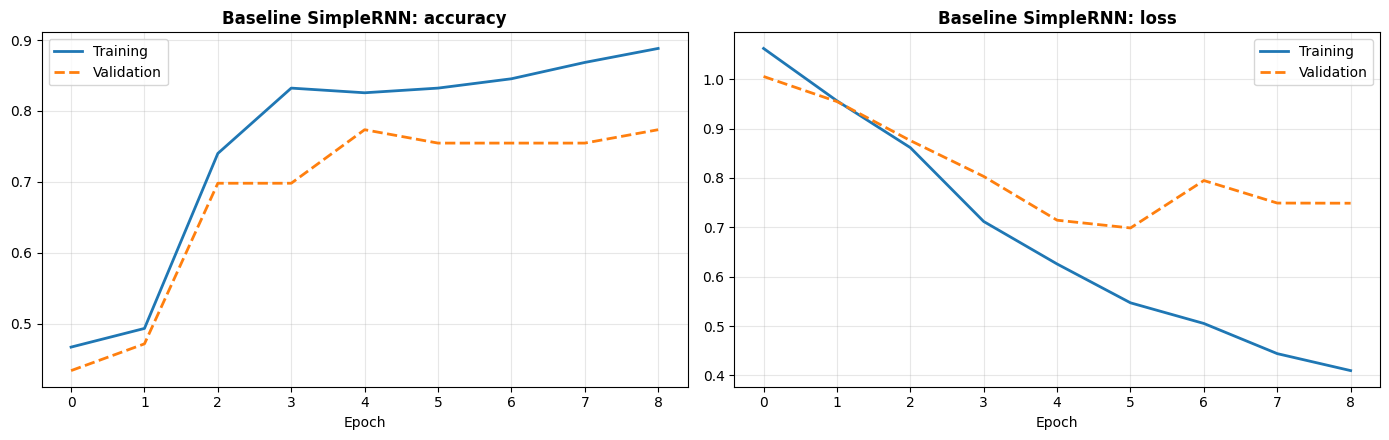

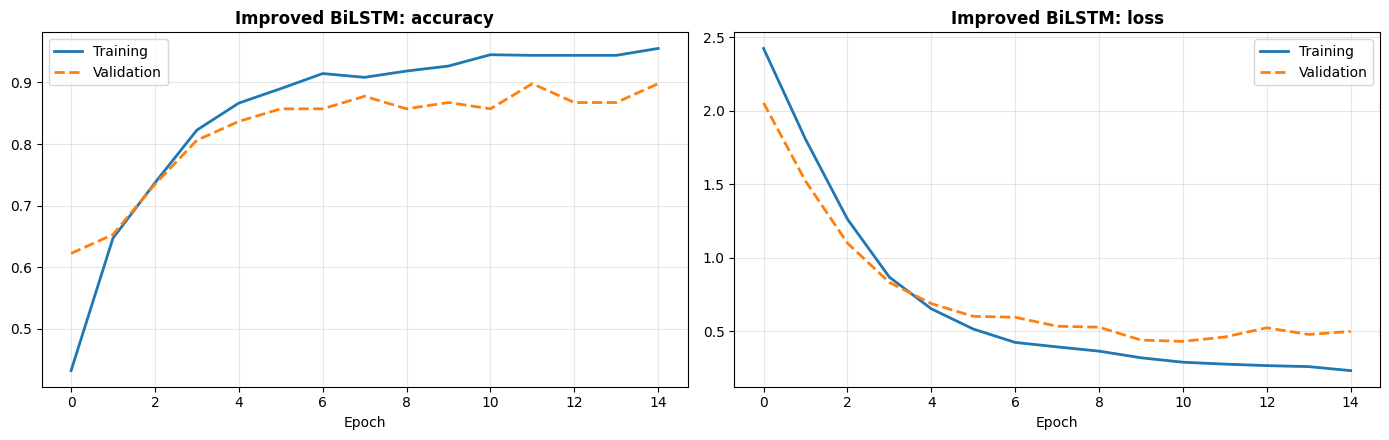

In [22]:
def plot_learning_curves(history, model_name):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    ax1.plot(history.history['accuracy'], label='Training', linewidth=2)
    ax1.plot(history.history['val_accuracy'], label='Validation', linewidth=2, linestyle='--')
    ax1.set_title(f'{model_name}: accuracy', fontweight='bold')
    ax1.set_xlabel('Epoch'); ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(history.history['loss'], label='Training', linewidth=2)
    ax2.plot(history.history['val_loss'], label='Validation', linewidth=2, linestyle='--')
    ax2.set_title(f'{model_name}: loss', fontweight='bold')
    ax2.set_xlabel('Epoch'); ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_learning_curves(base_history, "Baseline SimpleRNN")
plot_learning_curves(imp_history, "Improved BiLSTM")

**Observations**

- **Baseline:** training accuracy keeps rising (to about 89%) while validation accuracy levels off around 75–77%, and validation loss turns upward after epoch 6. That's overfitting on 304 reviews, and early stopping catches it.
- **BiLSTM:** training and validation track closely for the first 5 epochs, then validation accuracy settles around 86–90% while training accuracy reaches about 95%. The heavier regularisation keeps the gap smaller than the baseline's.

---
## 7. Evaluation on the same test reviews

Both models are scored on exactly the same test reviews, in two ways:

1. **English test reviews:** the baseline's home ground, since it was trained only on English
2. **All test reviews:** Malay reviews are translated for both models, so the baseline gets English text too

Each model receives the text in the format it was trained on: plain English for the baseline, lemmatised text for the improved model.

In [23]:
class_names = ['Negative', 'Neutral', 'Positive']

def predict(model, encode, texts):
    probs = model.predict(encode(texts), verbose=0)
    return probs, probs.argmax(axis=1)

def scores(y_true, y_pred):
    return {
        'Accuracy': (y_true == y_pred).mean(),
        'Macro F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Macro precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Macro recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
    }

# Each model gets the test reviews in its own input format:
# the baseline reads plain English (Malay reviews translated), the improved model reads lemmatised text
y_test, y_test_en = test_df['Label'].values, test_en['Label'].values
_, base_pred_en  = predict(base_model, encode_base, test_en['Review_en'])
_, base_pred_all = predict(base_model, encode_base, test_df['Review_en'])
_, imp_pred_en   = predict(imp_model, encode_imp, test_en['Review_lemma'])
imp_prob_all, imp_pred_all = predict(imp_model, encode_imp, test_df['Review_lemma'])

rows = []
for test_name, y_true, preds in [
        (f'English test reviews (n={len(test_en)})', y_test_en, {'Baseline SimpleRNN': base_pred_en, 'Improved BiLSTM': imp_pred_en}),
        (f'All test reviews, Malay translated (n={len(test_df)})', y_test, {'Baseline SimpleRNN': base_pred_all, 'Improved BiLSTM': imp_pred_all})]:
    for model_name, y_pred in preds.items():
        rows.append({'Test set': test_name, 'Model': model_name, **scores(y_true, y_pred)})

comparison_df = pd.DataFrame(rows)
comparison_df['Parameters'] = comparison_df['Model'].map({'Baseline SimpleRNN': base_model.count_params(),
                                                          'Improved BiLSTM': imp_model.count_params()})
comparison_df.round(3)

,Test set,Model,Accuracy,Macro F1,Macro precision,Macro recall,Parameters
0,English test reviews (n=63),Baseline SimpleRNN,0.857,0.853,0.857,0.859,4851
1,English test reviews (n=63),Improved BiLSTM,0.778,0.771,0.773,0.771,48515
2,"All test reviews, Malay translated (n=115)",Baseline SimpleRNN,0.696,0.688,0.691,0.702,4851
3,"All test reviews, Malay translated (n=115)",Improved BiLSTM,0.817,0.808,0.809,0.814,48515


**Results (seed 42)**

| Test set | Baseline SimpleRNN | Improved BiLSTM |
|---|:-:|:-:|
| English test reviews (63) | **85.7%** (macro F1 0.85) | 77.8% (macro F1 0.77) |
| All test reviews (115) | 69.6% (macro F1 0.69) | **81.7%** (macro F1 0.81) |

On the same test reviews, the result splits in two:

- **On English reviews, the simple baseline is better.**
- **Across all reviews, the BiLSTM is much better.** Of the 52 translated Malay test reviews, the baseline gets only 26 right (50%), against 45 (87%) for the BiLSTM. The translated reviews are worded differently: *"delicious"*, for example, appears 85 times in the translations but only 13 times in the English reviews.

These numbers come from one training run. The next section checks how much they move with the random seed.

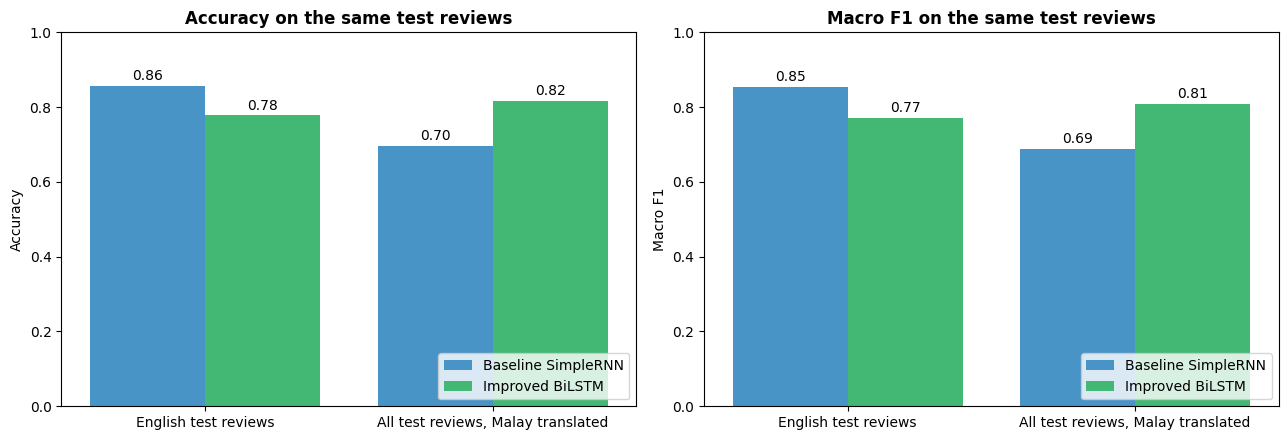

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ['Accuracy', 'Macro F1']):
    plot_df = comparison_df.copy()
    plot_df['Test set'] = plot_df['Test set'].str.replace(r' \(n=.*', '', regex=True)
    sns.barplot(data=plot_df, x='Test set', y=metric, hue='Model', palette=['#3498db', '#2ecc71'], ax=ax)
    ax.set_ylim(0, 1)
    ax.set_title(f'{metric} on the same test reviews', fontweight='bold')
    ax.set_xlabel('')
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=2)
    ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 7.1 Stability across random seeds

With only 63–115 test reviews, one review is worth 1–1.6 percentage points, and a single training run can be lucky or unlucky. Here both models are retrained with 5 different seeds. Everything else stays fixed: the data, split, tokenizers and the tuned hyperparameters.

In [25]:
# Same data, split, tokenizers and hyperparameters; only the random seed changes
# (weight initialisation, dropout masks and batch order)
def build_baseline():
    model = Sequential([
        Embedding(input_dim=MAX_WORDS, output_dim=16, input_length=MAX_LEN, mask_zero=True),
        SimpleRNN(32),
        Dense(3, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

SEEDS = [0, 1, 2, 3, 4]
seed_rows = []
start = time.time()
for seed in SEEDS:
    seed_everything(seed)
    b = build_baseline()
    b.fit(X_train_base, y_train_base, validation_data=(X_val_base, y_val_base), epochs=15, batch_size=32,
          class_weight=class_weights_base, verbose=0,
          callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)])

    seed_everything(seed)
    m = tuner.hypermodel.build(best_hps)
    m.fit(X_train_imp, y_train_imp, validation_data=(X_val_imp, y_val_imp), epochs=20, batch_size=32,
          class_weight=class_weights_imp, verbose=0,
          callbacks=[EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)])

    for model_name, model, encode, column in [('Baseline SimpleRNN', b, encode_base, 'Review_en'),
                                              ('Improved BiLSTM', m, encode_imp, 'Review_lemma')]:
        for test_name, part in [('English test reviews', test_en), ('All test reviews', test_df)]:
            _, pred = predict(model, encode, part[column])
            s = scores(part['Label'].values, pred)
            seed_rows.append({'Seed': seed, 'Model': model_name, 'Test set': test_name,
                              'Accuracy': s['Accuracy'], 'Macro F1': s['Macro F1']})

seed_df = pd.DataFrame(seed_rows)
print(f"{len(SEEDS)} seeds x 2 models trained in {(time.time() - start) / 60:.1f} min\n")
print(seed_df.pivot_table(index=['Test set', 'Model'], columns='Seed', values='Accuracy').round(3).to_string())
seed_df.groupby(['Test set', 'Model'])[['Accuracy', 'Macro F1']].agg(['mean', 'std', 'min', 'max']).round(3)

5 seeds x 2 models trained in 2.0 min

Seed                                         0      1      2      3      4
Test set             Model                                                
All test reviews     Baseline SimpleRNN  0.757  0.739  0.748  0.696  0.722
                     Improved BiLSTM     0.826  0.826  0.870  0.878  0.870
English test reviews Baseline SimpleRNN  0.937  0.905  0.905  0.841  0.921
                     Improved BiLSTM     0.810  0.810  0.857  0.857  0.857


Accuracy                       \
                                            mean    std    min    max   
Test set             Model                                              
All test reviews     Baseline SimpleRNN    0.732  0.024  0.696  0.757   
                     Improved BiLSTM       0.854  0.026  0.826  0.878   
English test reviews Baseline SimpleRNN    0.902  0.036  0.841  0.937   
                     Improved BiLSTM       0.838  0.026  0.810  0.857   

                                        Macro F1                       
                                            mean    std    min    max  
Test set             Model                                             
All test reviews     Baseline SimpleRNN    0.728  0.028  0.682  0.756  
                     Improved BiLSTM       0.844  0.025  0.816  0.874  
English test reviews Baseline SimpleRNN    0.900  0.041  0.831  0.937  
                     Improved BiLSTM       0.834  0.026  0.806  0.857

**Results over 5 seeds (mean ± standard deviation)**

| Test set | Baseline SimpleRNN | Improved BiLSTM |
|---|:-:|:-:|
| English test reviews (63) | **90.2% ± 3.6** (macro F1 0.90) | 83.8% ± 2.6 (macro F1 0.83) |
| All test reviews (115) | 73.2% ± 2.4 (macro F1 0.73) | **85.4% ± 2.6** (macro F1 0.84) |

The pattern is consistent:

- **English reviews:** the baseline wins in 4 of 5 seeds (seed 3 is the exception), by about 6 points on average.
- **All reviews:** the BiLSTM beats the baseline in all 5 seeds, by about 12 points on average.

So the BiLSTM's advantage comes from **covering the Malay half of the data**, not from being a better model of English text. Several changes could explain why it does worse on English reviews: half its training text is translated, the augmentation adds noisy sentences, and its hyperparameters were tuned on a mixed English–Malay validation set. An ablation (changing one thing at a time) would show which matters.

---
## 8. Per-class results (all test reviews)

In [26]:
print("=== Baseline SimpleRNN, all test reviews ===")
print(classification_report(y_test, base_pred_all, target_names=class_names, zero_division=0))
print("=== Improved BiLSTM, all test reviews ===")
print(classification_report(y_test, imp_pred_all, target_names=class_names, zero_division=0))

=== Baseline SimpleRNN, all test reviews ===
              precision    recall  f1-score   support

    Negative       0.63      0.82      0.71        33
     Neutral       0.59      0.63      0.61        30
    Positive       0.85      0.65      0.74        52

    accuracy                           0.70       115
   macro avg       0.69      0.70      0.69       115
weighted avg       0.72      0.70      0.70       115

=== Improved BiLSTM, all test reviews ===
              precision    recall  f1-score   support

    Negative       0.70      0.85      0.77        33
     Neutral       0.79      0.77      0.78        30
    Positive       0.93      0.83      0.88        52

    accuracy                           0.82       115
   macro avg       0.81      0.81      0.81       115
weighted avg       0.83      0.82      0.82       115



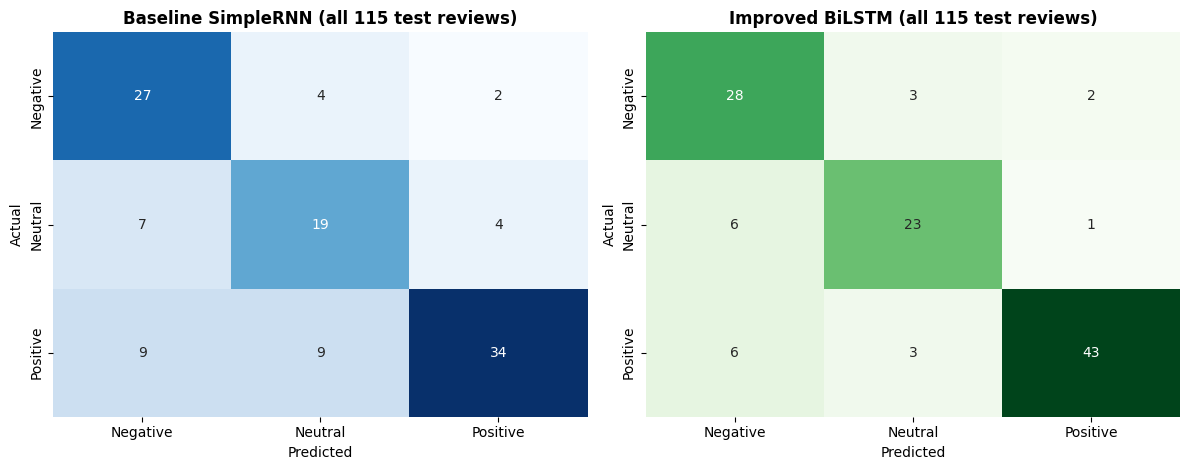

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (title, y_pred, cmap) in zip(axes, [('Baseline SimpleRNN', base_pred_all, 'Blues'),
                                            ('Improved BiLSTM', imp_pred_all, 'Greens')]):
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap=cmap, cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f'{title} (all {len(y_test)} test reviews)', fontweight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

**Observations**

- **Baseline:** most of its errors are positive reviews predicted as negative or neutral (18 of 52), and 14 of those 18 are translated Malay reviews. Neutral is its weakest class (19 of 30 correct).
- **BiLSTM:** positive reviews are recognised well (43 of 52, precision 0.93). Neutral is still the hardest class (23 of 30), and the most common errors are neutral and positive reviews predicted as negative (6 each).

---
## 9. Error analysis (improved model, all test reviews)

In [28]:
errors = test_df.assign(Actual=[class_names[c] for c in y_test],
                        Predicted=[class_names[c] for c in imp_pred_all],
                        Confidence=imp_prob_all.max(axis=1).round(3))
errors = errors[errors['Actual'] != errors['Predicted']]

print(f"Misclassified: {len(errors)} of {len(test_df)} test reviews ({len(errors) / len(test_df) * 100:.1f}%)")
print("\nErrors by actual class:")
print(errors['Actual'].value_counts())
print("\nAll misclassified reviews (English text the model saw, before lemmatisation):")
pd.set_option('display.max_colwidth', 90)
errors[['Review_en', 'Language', 'Actual', 'Predicted', 'Confidence']].sort_values('Actual')

Misclassified: 21 of 115 test reviews (18.3%)

Errors by actual class:
Actual
Positive    9
Neutral     7
Negative    5
Name: count, dtype: int64

All misclassified reviews (English text the model saw, before lemmatisation):


,Review_en,Language,Actual,Predicted,Confidence
754,really bad combination of flavors.,english,Negative,Positive,0.842
4,"crust was soggy, and the satay sauce didn’t help. sambal was okay but not balanced.",english,Negative,Neutral,0.998
366,"texture was chewy and rubbery, really bad.",english,Negative,Positive,0.524
318,"flavors clashed horribly, nothing worked.",english,Negative,Neutral,0.645
723,not suitable for my taste.,english,Negative,Neutral,0.571
458,the mayonnaise is too strong and spoils the taste of the pizza.,malay,Neutral,Negative,0.989
253,the fusion concept was interesting but not fully realized.,english,Neutral,Negative,0.838
439,the mayonnaise is too dominant and spoils the taste.,malay,Neutral,Negative,0.961
251,sambal was present but not very flavorful.,english,Neutral,Positive,0.625
199,satay flavor was present but not very strong.,english,Neutral,Negative,0.592


**What goes wrong** (21 errors out of 115)

1. **Lukewarm reviews read as negative.** *"satay flavor was present but not very strong"* and *"sambal was a bit bland for a spicy sauce"* are labelled neutral, but their words lean negative.
2. **Negation.** *"this pizza is very tasty and never disappoints"* is predicted negative, probably because of *"disappoints"*.
3. **Rare positive words.** *"exceptional flavor harmony…"* and *"unexpected harmony"* probably use words that appear rarely in training.
4. **Label noise.** Some neutral reviews read like complaints (*"the mayonnaise is too strong and spoils the taste"*), so predicting negative is arguably reasonable. The 0–10 scores map to sentiment imperfectly.
5. **Mixed reviews.** *"crust was soggy… sambal was okay but not balanced"* is labelled negative and predicted neutral.

---
## 10. Limitations

| Limitation | Impact | Next step |
|------------|--------|-----------|
| Small data (553 training, 115 test reviews) | One review moves test accuracy by about 1 point; results vary with the seed | Report several seeds (done here); collect more reviews |
| Several changes at once | Can't tell which change hurts the BiLSTM on English reviews | Ablation: translation, augmentation, lemmatisation and architecture one at a time |
| Hyperparameters tuned on 98 validation reviews | The chosen settings are uncertain | Cross-validated tuning |
| AI-generated translations | Translation choices affect the vocabulary: British spelling alone changed results until it was fixed | Spot-check translations with a Malay speaker; try a multilingual model that needs no translation |
| Negation and mixed reviews | Main error types | Pre-trained embeddings (GloVe, fastText) or a small pre-trained transformer |
| Noisy labels | Score-to-sentiment thresholds (≤ 4, ≤ 6) put some complaints in "neutral" | Review borderline labels, or predict the score directly |

---
## 11. Conclusion

**Setup:** 902 raw reviews were cleaned to 766 English and Malay reviews. One stratified split was shared by both models, tokenizers were fitted on training text only, and both models were scored on the same test reviews.

**Results (5 seeds)**

| Model | Parameters | English test reviews | All test reviews |
|---|:-:|:-:|:-:|
| Baseline SimpleRNN (English training data) | 4,851 | **90.2% ± 3.6** | 73.2% ± 2.4 |
| Improved BiLSTM (English + translated Malay, augmentation, tuning) | 48,515 | 83.8% ± 2.6 | **85.4% ± 2.6** |

**Key findings**
1. **Data coverage mattered most.** Translating the Malay reviews lets one model handle the whole dataset. The English-only baseline gets only about half of the translated reviews right.
2. **A bigger model isn't automatically better.** On English reviews alone, the 4,851-parameter SimpleRNN beats the 48,515-parameter BiLSTM.
3. **Fair evaluation changes the story.** An earlier version of this notebook compared the models on different test sets and reported the BiLSTM as better overall. Scoring both on the same reviews, over several seeds, shows the gain is specific to the Malay reviews.
4. **Small datasets need several runs.** Across seeds alone, the baseline's English accuracy ranged from 84.1% to 93.7%, so a single run can mislead; averages over several seeds are more reliable.